In [12]:
%load_ext autoreload
%autoreload 2

import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd().parent))
from viz_style import apply_style

import MixedEffectsModeling.config as config

# the sweep's own modules live beside its cache, not next to this notebook
sys.path.insert(0, str(config.METHOD_COMP_DIR))
from common import ARMS, COLORS, LABELS, Q_LEVELS, Q_MARKERS, SPLIT_TITLE, STYLES

apply_style()

CACHE = config.METHOD_COMP_CACHE_DIR
FIGDIR = config.METHOD_COMP_FIG_DIR
FIGDIR.mkdir(parents=True, exist_ok=True)

LOG2FCS_SHOWN = [2.0, 3.0, 4.0, 5.0]


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
D = pickle.loads((CACHE / "plot_data.pkl").read_bytes())
Q_GRID, RECALL_GRID = D["q_grid"], D["recall_grid"]
print(sorted({f for f, _ in D["cv"]["curves"]}), "log2FC levels cached")

[2.0, 3.0, 4.0, 5.0] log2FC levels cached


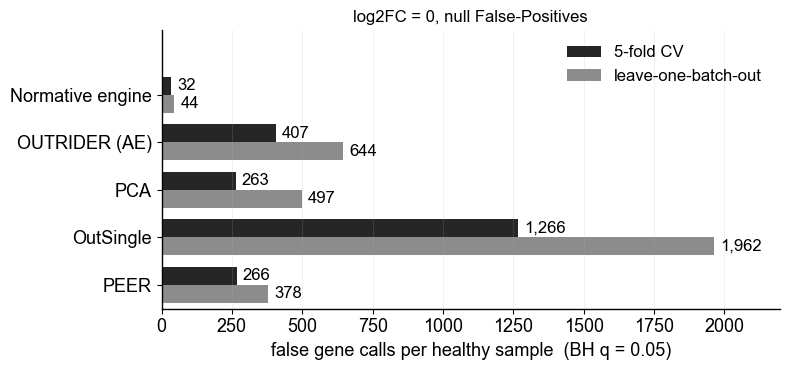

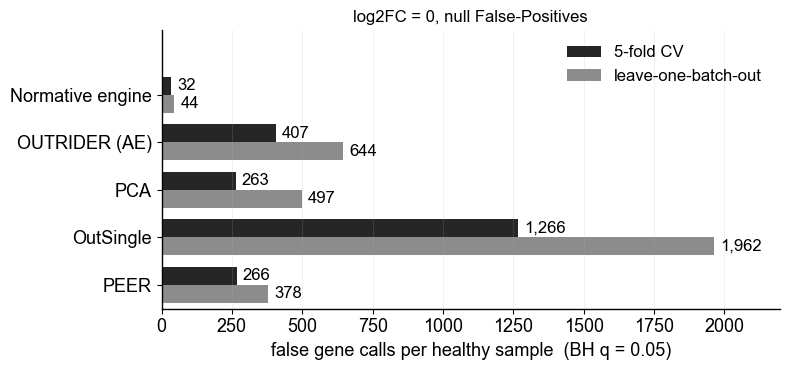

In [18]:
def null_falsecalls(q=0.05, save=True):
    n_genes = len((CACHE / "eval_universe_nm.txt").read_text().split())
    lg = np.log10(np.maximum(Q_GRID, 1e-12))
    rate = lambda sp, a: np.interp(np.log10(q), lg, D["null"][(sp, a)])
    fig, ax = plt.subplots(figsize=(8.0, 3.8))
    h = 0.38
    xmax = max(rate(sp, a) for sp in ("cv", "lobo") for a in ARMS) * n_genes * 1.12
    for k, split in enumerate(("cv", "lobo")):
        y = np.arange(len(ARMS)) + (k - 0.5) * h
        val = np.array([rate(split, a) * n_genes for a in ARMS])
        ax.barh(y, val, height=h, color="0.15" if split == "cv" else "0.55",
                edgecolor="none", label=SPLIT_TITLE[split])
        for yi, v in zip(y, val):
            ax.text(v + xmax * 0.01, yi, f"{v:,.0f}", va="center", fontsize=12)
    ax.set_xlim(0, xmax); ax.set_ylim(len(ARMS) - 0.5, -1.35)
    ax.set_yticks(range(len(ARMS))); ax.set_yticklabels([LABELS[a] for a in ARMS])
    ax.set_xlabel(f"false gene calls per healthy sample  (BH q = {q:g})")
    ax.grid(axis="x", alpha=0.25, lw=0.5)
    ax.legend(frameon=False, fontsize=12, loc="upper right", ncol=1, bbox_to_anchor=(0.995, 1.0))
    ax.set_title("log2FC = 0, null False-Positives", fontsize=12)
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "null_falsecalls.png", dpi=300, bbox_inches="tight")
    return fig

null_falsecalls()

In [15]:
# Inflation factor: observed / nominal. 1.0 = perfectly calibrated, >1 = anti-conservative.
import pandas as pd

alphas = [1e-4, 1e-3, 1e-2, 0.05]
idx = np.searchsorted(Q_GRID, alphas)
rows = {(SPLIT_TITLE[s], LABELS[a]): D["pcal"][(s, a)][idx] / np.array(alphas)
        for s in ("cv", "lobo") for a in ARMS}
pd.DataFrame(rows, index=[f"alpha={a:g}" for a in alphas]).T.round(2)

alpha=0.0001  alpha=0.001  alpha=0.01  \
5-fold CV           Normative engine         11.48         3.54        1.60   
                    OUTRIDER (AE)           179.81        25.03        4.19   
                    PCA                      98.96        15.51        2.87   
                    OutSingle               467.77        68.08       11.23   
                    PEER                     87.97        15.36        3.28   
leave-one-batch-out Normative engine         16.03         4.30        1.67   
                    OUTRIDER (AE)           283.60        39.46        6.56   
                    PCA                     197.53        29.17        5.00   
                    OutSingle               708.54       102.85       16.78   
                    PEER                    138.36        22.75        4.59   

                                      alpha=0.05  
5-fold CV           Normative engine        1.19  
                    OUTRIDER (AE)           1.51  
                    PCA                     1.10  
                    OutSingle               3.65  
                    PEER                    1.39  
leave-one-batch-out Normative engine        1.16  
                    OUTRIDER (AE)           2.27  
                    PCA                     1.75  
                    OutSingle               5.29  
                    PEER                    1.89

In [16]:
def pr_grid(log2fcs=LOG2FCS_SHOWN, splits=("cv", "lobo"), arms=ARMS, band=True, save=True):
    """Line = per-fold median, ribbon = fold IQR, markers = the reported BH levels placed at
    the median recall reached there and read off the curve, so they sit ON the line."""
    fig, axes = plt.subplots(len(splits), len(log2fcs),
                             figsize=(2.7 * len(log2fcs), 2.4 * len(splits)),
                             sharex=True, sharey=True, squeeze=False)
    for i, split in enumerate(splits):
        for j, f in enumerate(log2fcs):
            ax = axes[i, j]
            bands, ops = D[split]["bands"], D[split]["ops"]
            for arm in arms:
                lo, med, hi = bands[(f, arm)]
                if band:
                    ax.fill_between(RECALL_GRID, lo, hi, color=COLORS[arm], alpha=0.15, lw=0)
                ax.plot(RECALL_GRID, med, color=COLORS[arm], ls=STYLES[arm],
                        lw=2.0 if arm == "engine" else 1.4,
                        label=LABELS[arm] if (i, j) == (0, 0) else None,
                        zorder=4 if arm == "engine" else 3)
                for q in Q_LEVELS:
                    r = ops[("med", q, f, arm)][0]
                    ax.plot(r, np.interp(r, RECALL_GRID, med), marker=Q_MARKERS[q], ms=6,
                            color=COLORS[arm], mec="white", mew=0.6, ls="none", zorder=5)
            ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
            ax.grid(alpha=0.2, lw=0.5)
            if i == 0:
                ax.set_title(f"log2FC = {f:g}")
            if j == len(log2fcs) - 1:
                ax.text(1.06, 0.5, SPLIT_TITLE[split], rotation=270, va="center",
                        ha="left", fontsize=12, transform=ax.transAxes,
                        bbox=dict(facecolor="0.92", edgecolor="none", pad=3))
            if j == 0:
                ax.set_ylabel("Precision")
            if i == len(splits) - 1:
                ax.set_xlabel("Recall")
    h, l = axes[0, 0].get_legend_handles_labels()
    leg = fig.legend(h, l, loc="upper left", bbox_to_anchor=(1.02, 0.95), frameon=False,
                     fontsize=12, title="Method")
    leg.get_title().set_fontsize(12)
    qh = [plt.Line2D([], [], marker=m, ls="none", color="0.3", ms=4, mec="white", mew=0.6)
          for m in Q_MARKERS.values()]
    leg2 = fig.legend(qh, [str(q) for q in Q_MARKERS], loc="upper left",
                      bbox_to_anchor=(1.02, 0.55), frameon=False, fontsize=12, title="BH q")
    leg2.get_title().set_fontsize(12)
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "pr_grid.png", dpi=300, bbox_inches="tight")
    return fig

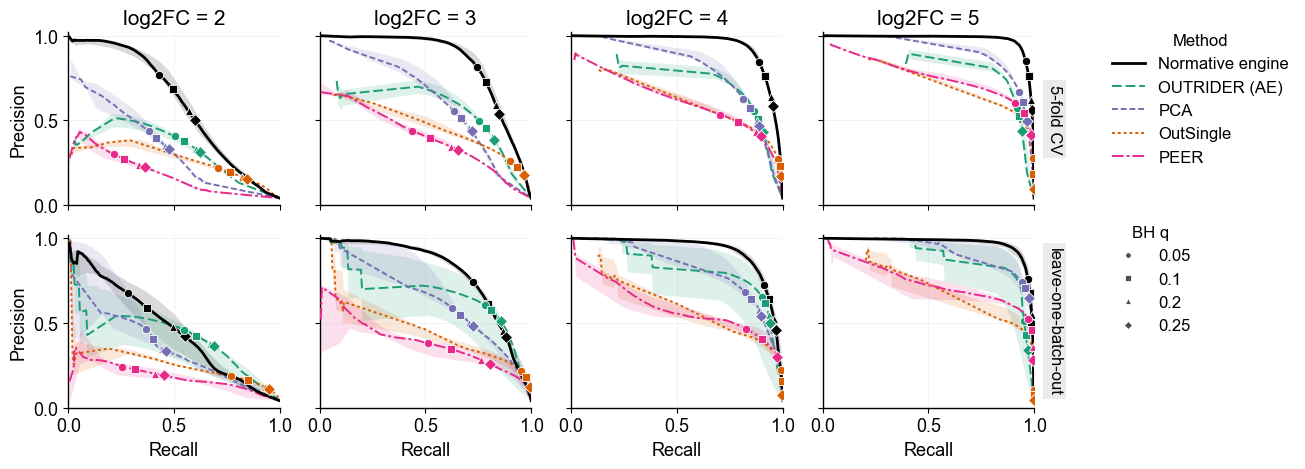

In [17]:
pr_grid();

In [34]:
def persample_confusion(q=0.05):
    c = pd.read_csv(CACHE / "sweep_nm_counts.csv")
    c = c[c["q"] == q].groupby(["split", "arm", "log2fc"])[["tp", "fp", "fn", "tn", "n_samples"]].sum()
    out = c[["tp", "fp", "fn", "tn"]].div(c["n_samples"], axis=0)
    out.columns = ["TP", "FP", "FN", "TN"]
    return out


CONF = persample_confusion()
CONF.unstack("log2fc").round(1)

TP                                         FP          \
log2fc              0.0    1.0    2.0    3.0    4.0    5.0     0.0     1.0   
split arm                                                                    
cv    autoencoder  16.7   76.0  253.5  377.1  435.4  460.9   390.0   386.3   
      engine        1.3   14.2  214.9  369.3  445.3  479.7    31.0    34.9   
      outsingle    52.4  177.8  352.7  450.0  488.6  497.4  1213.9  1232.1   
      pca          11.0   46.5  192.2  322.3  409.9  466.1   251.8   241.2   
      peer         11.1   28.6  109.0  223.9  356.3  458.2   255.3   253.9   
lobo  autoencoder  26.4   97.2  273.5  399.4  450.4  470.6   617.3   604.4   
      engine        1.8    8.8  150.6  329.9  425.3  471.3    42.4    45.0   
      outsingle    80.0  206.8  382.8  472.0  494.5  499.0  1882.2  1894.7   
      pca          20.3   70.8  215.6  340.2  428.1  475.6   477.1   461.8   
      peer         15.4   35.7  123.1  246.9  386.0  475.4   362.3   366.0   

                                   ...     FN                           TN  \
log2fc                2.0     3.0  ...    2.0    3.0    4.0   5.0      0.0   
split arm                          ...                                       
cv    autoencoder   384.2   377.8  ...  246.5  122.9   64.6  39.1  11198.0   
      engine         53.8    68.1  ...  285.1  130.7   54.7  20.3  11557.0   
      outsingle    1275.1  1302.5  ...  147.3   50.0   11.4   2.6  10374.1   
      pca           251.2   253.6  ...  307.8  177.7   90.1  33.9  11336.2   
      peer          273.0   293.2  ...  391.0  276.1  143.7  41.8  11332.7   
lobo  autoencoder   605.8   600.4  ...  226.5  100.6   49.6  29.4  10970.7   
      engine         62.9    78.9  ...  349.4  170.1   74.7  28.7  11545.6   
      outsingle    1949.4  1984.0  ...  117.2   28.0    5.5   1.0   9705.8   
      pca           476.1   477.6  ...  284.4  159.8   71.9  24.4  11110.9   
      peer          394.2   423.6  ...  376.9  253.1  114.0  24.6  11225.7   

                                                                
log2fc                 1.0      2.0      3.0      4.0      5.0  
split arm                                                       
cv    autoencoder  11201.7  11203.8  11210.2  11217.8  11224.5  
      engine       11553.1  11534.2  11519.9  11511.9  11508.0  
      outsingle    10355.9  10312.9  10285.5  10263.1  10237.3  
      pca          11346.8  11336.8  11334.4  11336.6  11339.8  
      peer         11334.1  11315.0  11294.8  11278.8  11269.4  
lobo  autoencoder  10983.6  10982.2  10987.6  10996.1  11002.7  
      engine       11543.0  11525.1  11509.1  11501.0  11496.9  
      outsingle     9693.3   9638.6   9604.0   9578.0   9546.6  
      pca          11126.2  11111.9  11110.4  11113.8  11119.0  
      peer         11222.0  11193.8  11164.4  11141.8  11129.2  

[10 rows x 24 columns]

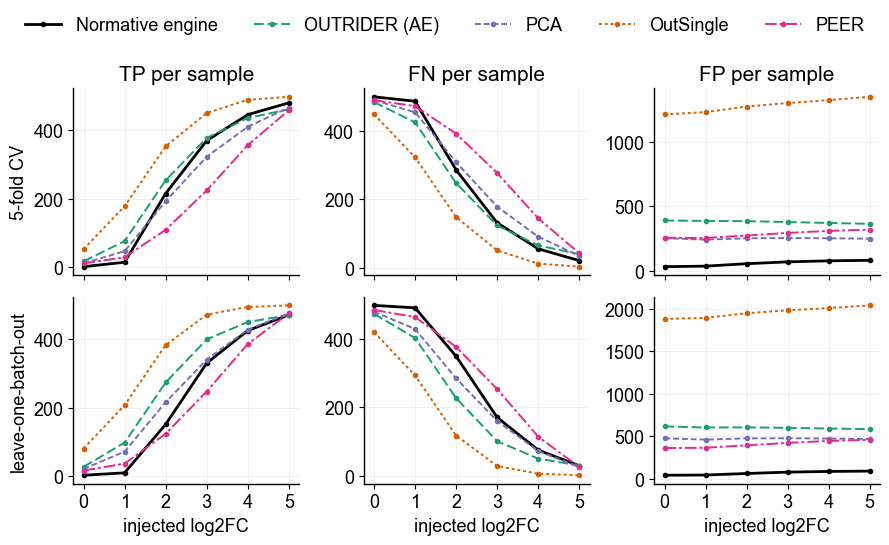

In [33]:
def confusion_panels(conf=CONF, splits=("cv", "lobo"), arms=ARMS, save=True):
    metrics = ["TP", "FN", "FP"]
    fig, axes = plt.subplots(len(splits), len(metrics), figsize=(3 * len(metrics), 2.5 * len(splits)),
                             sharex=True, squeeze=False)
    for i, split in enumerate(splits):
        for j, m in enumerate(metrics):
            ax = axes[i, j]
            for arm in arms:
                s = conf.loc[(split, arm), m]
                ax.plot(s.index, s.values, color=COLORS[arm], ls=STYLES[arm], marker="o", ms=3,
                        lw=2.0 if arm == "engine" else 1.4, label=LABELS[arm] if (i, j) == (0, 0) else None)
            if i == 0:
                ax.set_title(f"{m} per sample")
            if j == 0:
                ax.set_ylabel(SPLIT_TITLE[split])
            if i == len(splits) - 1:
                ax.set_xlabel("injected log2FC")
            ax.set_xticks(conf.index.get_level_values("log2fc").unique())
            ax.grid(alpha=0.25, lw=0.5)
    fig.legend(loc="upper center", ncol=len(arms), frameon=False, bbox_to_anchor=(0.5, 1.1))
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "persample_confusion.png", dpi=300, bbox_inches="tight")
    return fig


confusion_panels();